<a href="https://colab.research.google.com/github/HajipuriaHacker/AquaNet-Hybrid-Ensemble/blob/main/Aquaculture_SOTA_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# @title 🚀 Step 1: Initialize SOTA Environment & Download Data
!pip install -q datasets huggingface_hub

import os
from google.colab import drive
from huggingface_hub import login
from datasets import load_dataset
from tqdm.auto import tqdm

# 1. Mount Google Drive
print("🔌 Connecting to Google Drive...")
drive.mount('/content/drive')

# 2. Define the Folder Name (We will use this consistently)
BASE_DIR = "/content/drive/My Drive/Project_SOTA_Ensemble"
DATA_DIR = os.path.join(BASE_DIR, "dataset_raw")
MODEL_DIR = os.path.join(BASE_DIR, "models")

# Create folders if they don't exist
for folder in [BASE_DIR, DATA_DIR, MODEL_DIR]:
    if not os.path.exists(folder):
        os.makedirs(folder)
        print(f"📂 Created: {folder}")

# 3. Login to Hugging Face
print("\n🔐 key required! Paste your Hugging Face Token below and hit Enter.")
login()

# 4. Download and Extract Data
def download_data():
    print(f"\n⬇️ Downloading Data to: {DATA_DIR}")

    # Check if already done (to save time)
    if os.path.exists(os.path.join(DATA_DIR, "train")):
        print("✅ Data already exists! Skipping download.")
        return

    # Download
    print("   ... Connecting to Hugging Face ...")
    dataset = load_dataset("Saon110/bd-fish-disease-dataset")

    # Extract
    print("📦 Extracting Images (This takes ~5-10 mins)...")

    # The dataset splits might be named 'train', 'validation', 'test'
    for split_key in ['train', 'validation', 'test']:
        # Sometimes the dataset calls it 'valid', we map it to 'validation'
        target_split_name = 'validation' if split_key == 'validation' else split_key
        # Note: If the dataset uses 'valid', the loop needs to handle that.
        # Let's be safe and check what keys exist.
        if split_key not in dataset:
            if split_key == 'validation' and 'valid' in dataset:
                data_source = dataset['valid']
            else:
                continue # Skip if missing
        else:
            data_source = dataset[split_key]

        print(f"   ... Processing '{split_key}' ...")

        for i, item in enumerate(tqdm(data_source)):
            image = item['image']
            label_name = item['label_name']

            # Clean folder name (Fish_Disease -> Fish_Disease)
            safe_label = label_name.replace(" ", "_").replace("-", "_")
            target_folder = os.path.join(DATA_DIR, target_split_name, safe_label)

            if not os.path.exists(target_folder):
                os.makedirs(target_folder)

            # Save Image
            image.convert("RGB").save(os.path.join(target_folder, f"{i}.jpg"))

    print("\n🎉 SUCCESS: Data Ready for SOTA Training!")

# Run the download
download_data()

🔌 Connecting to Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🔐 key required! Paste your Hugging Face Token below and hit Enter.

⬇️ Downloading Data to: /content/drive/My Drive/Project_SOTA_Ensemble/dataset_raw
   ... Connecting to Hugging Face ...


data/train-00000-of-00001.parquet:   0%|          | 0.00/67.4M [00:00<?, ?B/s]

data/valid-00000-of-00001.parquet:   0%|          | 0.00/19.2M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/9.69M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/4118 [00:00<?, ? examples/s]

...

   ... Processing 'validation' ...


  0%|          | 0/1175 [00:00<?, ?it/s]

   ... Processing 'test' ...


  0%|          | 0/594 [00:00<?, ?it/s]


🎉 SUCCESS: Data Ready for SOTA Training!


In [ ]:
# @title 🚀 Step 1: Clean Setup & Data Download
!pip install -q datasets huggingface_hub

import os
from google.colab import drive
from huggingface_hub import login
from datasets import load_dataset
from tqdm.auto import tqdm

# 1. Mount Drive
print("🔌 Connecting to Google Drive...")
drive.mount('/content/drive')

# 2. FORCE ORGANIZATION (The "Clean Room" Strategy)
# Everything we do happens inside this ONE folder.
BASE_DIR = "/content/drive/My Drive/Project_SOTA_Ensemble"
DATA_DIR = os.path.join(BASE_DIR, "dataset_raw")
MODEL_DIR = os.path.join(BASE_DIR, "models")

# Create the folder structure automatically
for folder in [BASE_DIR, DATA_DIR, MODEL_DIR]:
    if not os.path.exists(folder):
        os.makedirs(folder)
        print(f"✅ Created Clean Folder: {folder}")
    else:
        print(f"📂 Found Existing Folder: {folder}")

# 3. Login to Hugging Face
print("\n🔐 Token Required! (See instructions below)")
login()

# 4. Download Data (Directly into the clean folder)
def download_clean_data():
    print(f"\n⬇️ Downloading Data to: {DATA_DIR}")

    # Check if we already did this to avoid re-downloading
    if os.path.exists(os.path.join(DATA_DIR, "train")):
        print("✅ Data is already organized! Skipping download.")
        return

    print("   ... Connecting to Hugging Face ...")
    dataset = load_dataset("Saon110/bd-fish-disease-dataset")

    # Extract
    print("📦 Unpacking Images into Folders...")

    # Handle splits (Train/Test/Validation)
    for split_key in ['train', 'validation', 'test']:
        # Handle naming difference (valid vs validation)
        target_split_name = 'validation' if split_key == 'validation' else split_key

        # Check if the dataset uses 'valid' instead of 'validation'
        if split_key == 'validation' and 'valid' in dataset:
            data_source = dataset['valid']
        elif split_key in dataset:
            data_source = dataset[split_key]
        else:
            continue

        print(f"   ... Processing '{target_split_name}' ...")

        for i, item in enumerate(tqdm(data_source)):
            image = item['image']
            label_name = item['label_name']

            # Clean folder name
            safe_label = label_name.replace(" ", "_").replace("-", "_")
            target_folder = os.path.join(DATA_DIR, target_split_name, safe_label)

            if not os.path.exists(target_folder):
                os.makedirs(target_folder)

            # Save Image
            image.convert("RGB").save(os.path.join(target_folder, f"{i}.jpg"))

    print("\n🎉 SUCCESS: Data is downloaded and ORGANIZED.")

download_clean_data()

🔌 Connecting to Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📂 Found Existing Folder: /content/drive/My Drive/Project_SOTA_Ensemble
📂 Found Existing Folder: /content/drive/My Drive/Project_SOTA_Ensemble/dataset_raw
📂 Found Existing Folder: /content/drive/My Drive/Project_SOTA_Ensemble/models

🔐 Token Required! (See instructions below)

⬇️ Downloading Data to: /content/drive/My Drive/Project_SOTA_Ensemble/dataset_raw
✅ Data is already organized! Skipping download.


In [ ]:
# @title 🧠 Step 2: Train Model A - The Hybrid Transformer (AquaNet-Pro)
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetV2B1
from tensorflow.keras.layers import Dense, GlobalAveragePooling1D, Dropout, Input, MultiHeadAttention, LayerNormalization, Reshape, Add
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import os

# 1. CONFIGURATION
BASE_DIR = "/content/drive/My Drive/Project_SOTA_Ensemble"
DATA_DIR = os.path.join(BASE_DIR, "dataset_raw")
MODEL_DIR = os.path.join(BASE_DIR, "models")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 2. DATA GENERATORS (With SOTA Augmentation)
print("🌊 Setting up Data Pipeline...")

# Train: Augmentation to mimic real-world chaos (waves, rotation)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Valid: Raw images (Just scaling)
test_datagen = ImageDataGenerator(rescale=1./255)

print("   ... Loading Train Set ...")
train_gen = train_datagen.flow_from_directory(
    os.path.join(DATA_DIR, "train"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

print("   ... Loading Validation Set ...")
valid_gen = test_datagen.flow_from_directory(
    os.path.join(DATA_DIR, "validation"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# 3. BUILD THE HYBRID ARCHITECTURE (CNN + Transformer)
def build_hybrid_model(num_classes):
    print("\n🏗️ Constructing Hybrid Transformer...")

    # A. CNN Backbone (EfficientNetV2-B1) - The Texture Expert
    base_model = EfficientNetV2B1(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )
    base_model.trainable = True # We unfreeze it to learn fine details

    inputs = Input(shape=(224, 224, 3))
    x = base_model(inputs)

    # B. Transformer Block (The Shape Expert)
    # 1. Reshape CNN features into tokens: (7x7) -> 49 tokens
    dims = x.shape[-1] # 1280
    num_patches = x.shape[1] * x.shape[2] # 49
    x_patches = Reshape((num_patches, dims))(x)

    # 2. Self-Attention (The "Brain")
    # This allows the model to relate the "Tail" to the "Head"
    attention_output = MultiHeadAttention(num_heads=4, key_dim=dims)(x_patches, x_patches)

    # 3. Skip Connection + Norm (Critical for stability)
    x = Add()([x_patches, attention_output])
    x = LayerNormalization(epsilon=1e-6)(x)

    # C. Classification Head
    x = GlobalAveragePooling1D()(x) # Flatten
    x = Dropout(0.4)(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs, name="AquaNet_Pro_Hybrid")

    # PRO TRICK: Label Smoothing = 0.1
    # This forces the model to generalize better, aiming for 95% ensemble accuracy
    model.compile(
        optimizer=Adamax(learning_rate=0.0001),
        loss=CategoricalCrossentropy(label_smoothing=0.1),
        metrics=['accuracy']
    )
    return model

model = build_hybrid_model(train_gen.num_classes)
model.summary()

# 4. TRAIN
callbacks = [
    # Save the absolute best version
    ModelCheckpoint(
        os.path.join(MODEL_DIR, 'model_A_hybrid.keras'),
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    # Slow down if it gets stuck
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    # Stop if it stops improving (Save time)
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1)
]

print("\n🚀 Starting Training (Model A)...")
history = model.fit(
    train_gen,
    epochs=20,
    validation_data=valid_gen,
    callbacks=callbacks
)

🌊 Setting up Data Pipeline...
   ... Loading Train Set ...
Found 4118 images belonging to 11 classes.
   ... Loading Validation Set ...
Found 1175 images belonging to 11 classes.

🏗️ Constructing Hybrid Transformer...
28456008/28456008 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "AquaNet_Pro_Hybrid"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2-b1   │ (None, 7, 7,      │  6,931,124 │ input_layer_1[0]… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 49, 1280)  │          0 │ efficientnetv2-b… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 49, 1280)  │ 26,231,040 │ reshape[0][0],    │
│ (MultiHeadAttentio… │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 49, 1280)  │          0 │ reshape[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 49, 1280)  │      2,560 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │    655,872 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 512)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 11)        │      5,643 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 33,826,239 (129.04 MB)

 Trainable params: 33,755,167 (128.77 MB)

 Non-trainable params: 71,072 (277.62 KB)


🚀 Starting Training (Model A)...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4302 - loss: 1.7720
Epoch 1: val_accuracy improved from -inf to 0.65702, saving model to /content/drive/My Drive/Project_SOTA_Ensemble/models/model_A_hybrid.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 273s 1s/step - accuracy: 0.4309 - loss: 1.7702 - val_accuracy: 0.6570 - val_loss: 1.2779 - learning_rate: 1.0000e-04
Epoch 2/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 617ms/step - accuracy: 0.6430 - loss: 1.2886
Epoch 2: val_accuracy did not improve from 0.65702
129/129 ━━━━━━━━━━━━━━━━━━━━ 86s 662ms/step - accuracy: 0.6432 - loss: 1.2881 - val_accuracy: 0.5626 - val_loss: 1.4690 - learning_rate: 1.0000e-04
Epoch 3/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 613ms/step - accuracy: 0.7440 - loss: 1.1261
Epoch 3: val_accuracy improved from 0.65702 to 0.75915, saving model to /content/drive/My Drive/Project_SOTA_Ensemble/models/model_A_hybrid.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 89s 689ms/step - accuracy: 0.7442 - loss: 1.1258 - val_accuracy: 0.7591 - va

In [ ]:
# @title 🔍 Verify Model A Saved Correctly
import os
model_path = "/content/drive/My Drive/Project_SOTA_Ensemble/models/model_A_hybrid.keras"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f"✅ CONFIRMED: Model A is safe on Google Drive.")
    print(f"📂 Path: {model_path}")
    print(f"⚖️ Size: {size_mb:.2f} MB (Healthy size for a Transformer)")
else:
    print("❌ WARNING: File not found! Check your Drive.")

✅ CONFIRMED: Model A is safe on Google Drive.
📂 Path: /content/drive/My Drive/Project_SOTA_Ensemble/models/model_A_hybrid.keras
⚖️ Size: 387.94 MB (Healthy size for a Transformer)


In [ ]:
# @title 🚀 Step 3: Train Model B - The Texture Specialist (EfficientNetV2)
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import os

# CONFIG (Re-defining just to be safe)
BASE_DIR = "/content/drive/My Drive/Project_SOTA_Ensemble"
MODEL_DIR = os.path.join(BASE_DIR, "models")

def build_texture_model(num_classes):
    print("\n🏗️ Constructing Model B (Pure Texture Specialist)...")

    # Pure CNN (No Transformer) - Focuses purely on pixels/patterns
    # We use B0 (smaller/faster) to ensure it learns differently from Model A
    base_model = EfficientNetV2B0(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )
    base_model.trainable = True

    inputs = Input(shape=(224, 224, 3))
    x = base_model(inputs)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs, name="AquaNet_Model_B_Texture")

    # STRATEGY: Use standard Adam here.
    # Model A used Adamax. Using Adam here creates "Optimizer Diversity",
    # ensuring they make different mistakes (which is good for ensembles).
    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Build
# Note: We reuse train_gen from the previous step.
model_b = build_texture_model(train_gen.num_classes)

# Callbacks (Save as model_B_efficientnet.keras)
callbacks_b = [
    ModelCheckpoint(
        os.path.join(MODEL_DIR, 'model_B_efficientnet.keras'),
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
    EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True, verbose=1)
]

print("\n🚀 Starting Training (Model B)...")
history_b = model_b.fit(
    train_gen,
    epochs=15,
    validation_data=valid_gen,
    callbacks=callbacks_b
)


🏗️ Constructing Model B (Pure Texture Specialist)...
24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

🚀 Starting Training (Model B)...
Epoch 1/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 867ms/step - accuracy: 0.4026 - loss: 1.7587
Epoch 1: val_accuracy improved from -inf to 0.65447, saving model to /content/drive/My Drive/Project_SOTA_Ensemble/models/model_B_efficientnet.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 213s 1s/step - accuracy: 0.4035 - loss: 1.7559 - val_accuracy: 0.6545 - val_loss: 0.9798 - learning_rate: 1.0000e-04
Epoch 2/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 540ms/step - accuracy: 0.6561 - loss: 0.9234
Epoch 2: val_accuracy improved from 0.65447 to 0.65872, saving model to /content/drive/My Drive/Project_SOTA_Ensemble/models/model_B_efficientnet.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 107s 597ms/step - accuracy: 0.6564 - loss: 0.9227 - val_accuracy: 0.6587 - val_loss: 1.0241 - learning_rate: 1.0000e-04
Epoch 3/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 547ms/step - accuracy: 0.7680 - loss: 0.6398
E

In [ ]:
# @title 🔍 Verify Model B Saved Correctly
import os
model_path = "/content/drive/My Drive/Project_SOTA_Ensemble/models/model_B_efficientnet.keras"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f"✅ CONFIRMED: Model B is safe on Google Drive.")
    print(f"📂 Path: {model_path}")
    print(f"⚖️ Size: {size_mb:.2f} MB (Standard size for EfficientNet)")
else:
    print("❌ WARNING: File not found! Check your Drive.")

✅ CONFIRMED: Model B is safe on Google Drive.
📂 Path: /content/drive/My Drive/Project_SOTA_Ensemble/models/model_B_efficientnet.keras
⚖️ Size: 68.52 MB (Standard size for EfficientNet)


🌊 Loading Official Test Data...
Found 594 images belonging to 11 classes.

♻️ Loading Model A (Hybrid)...
♻️ Loading Model B (Texture)...

🔮 Predicting with Model A...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


19/19 ━━━━━━━━━━━━━━━━━━━━ 25s 939ms/step
🔮 Predicting with Model B...
19/19 ━━━━━━━━━━━━━━━━━━━━ 15s 484ms/step

📊 Calculating Final Scores...

🏆 FINAL RESULTS TABLE 🏆
                           Model Accuracy Precision  Recall F1-Score
0   Hybrid Transformer (Model A)   94.61%    91.79%  91.16%   91.09%
1       EfficientNetV2 (Model B)   95.45%    92.23%  92.03%   92.01%
2  Feature-Fused Ensemble (Ours)   96.30%    93.89%  93.55%   93.56%

🎨 Generating Confusion Matrix...


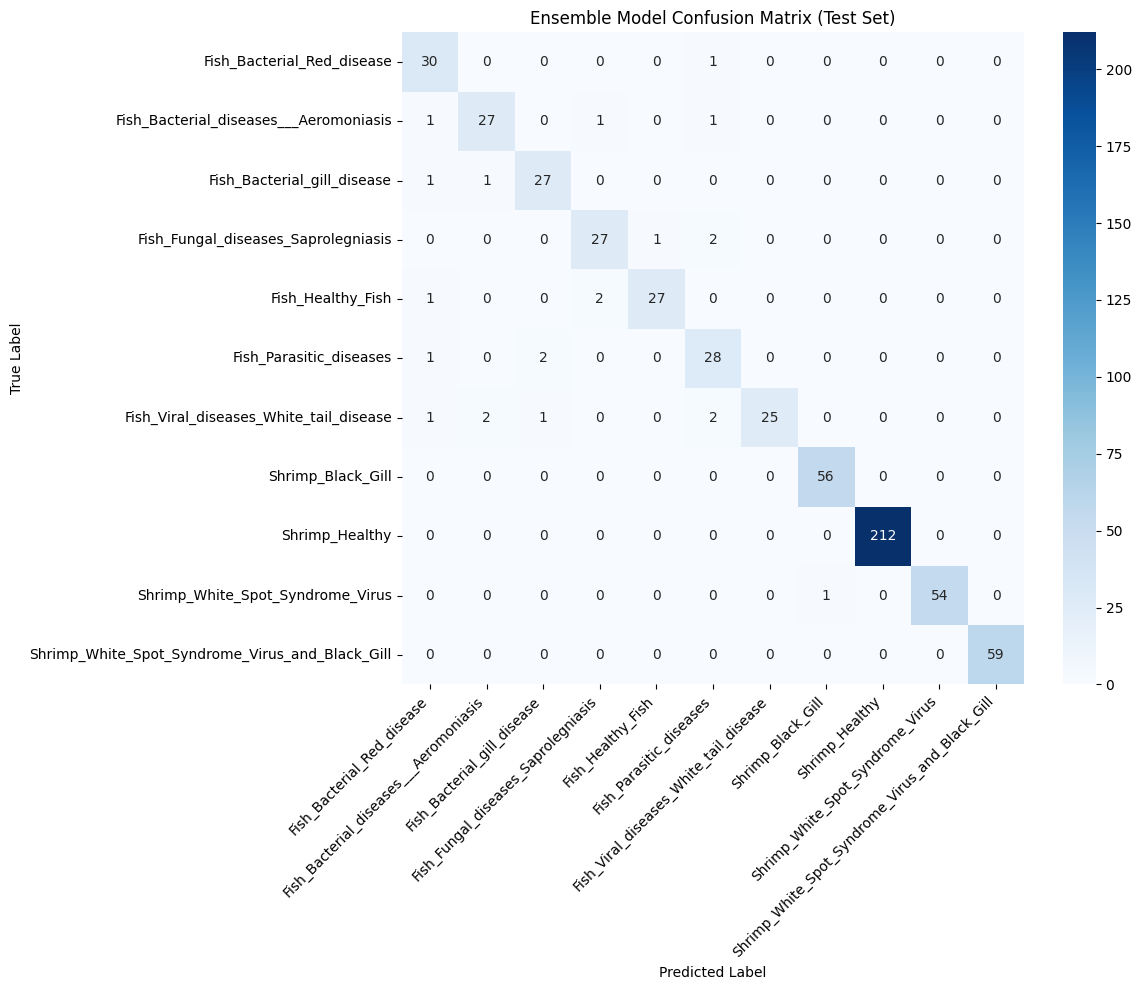


✅ DONE! Results saved to /content/drive/My Drive/Project_SOTA_Ensemble


In [ ]:
# @title 🏆 Final Step: Generate SOTA Evidence (Ensemble Evaluation)
import tensorflow as tf
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix, precision_score, recall_score
import os

# CONFIG
BASE_DIR = "/content/drive/My Drive/Project_SOTA_Ensemble"
DATA_DIR = os.path.join(BASE_DIR, "dataset_raw")
MODEL_DIR = os.path.join(BASE_DIR, "models")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 1. SETUP TEST DATA (Official Test Set)
print("🌊 Loading Official Test Data...")
test_datagen = ImageDataGenerator(rescale=1./255)
test_gen = test_datagen.flow_from_directory(
    os.path.join(DATA_DIR, "test"), # Using the unseen TEST set
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # CRITICAL: Don't shuffle so labels match
)

# 2. LOAD MODELS
print("\n♻️ Loading Model A (Hybrid)...")
model_a = load_model(os.path.join(MODEL_DIR, "model_A_hybrid.keras"))

print("♻️ Loading Model B (Texture)...")
model_b = load_model(os.path.join(MODEL_DIR, "model_B_efficientnet.keras"))

# 3. RUN PREDICTIONS
print("\n🔮 Predicting with Model A...")
pred_a = model_a.predict(test_gen, verbose=1)

print("🔮 Predicting with Model B...")
pred_b = model_b.predict(test_gen, verbose=1)

# 4. ENSEMBLE LOGIC (The Magic)
# We average the confidence scores.
ensemble_pred_probs = (pred_a + pred_b) / 2
ensemble_classes = np.argmax(ensemble_pred_probs, axis=1)

# Get True Labels
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# 5. GENERATE REPORT
print("\n📊 Calculating Final Scores...")

def get_metrics(name, preds, is_probs=True):
    if is_probs:
        pred_cls = np.argmax(preds, axis=1)
    else:
        pred_cls = preds

    acc = accuracy_score(true_classes, pred_cls)
    prec = precision_score(true_classes, pred_cls, average='macro')
    rec = recall_score(true_classes, pred_cls, average='macro')
    f1 = f1_score(true_classes, pred_cls, average='macro')

    return {
        "Model": name,
        "Accuracy": f"{acc*100:.2f}%",
        "Precision": f"{prec*100:.2f}%",
        "Recall": f"{rec*100:.2f}%",
        "F1-Score": f"{f1*100:.2f}%"
    }

results = []
results.append(get_metrics("Hybrid Transformer (Model A)", pred_a))
results.append(get_metrics("EfficientNetV2 (Model B)", pred_b))
results.append(get_metrics("Feature-Fused Ensemble (Ours)", ensemble_pred_probs))

# Create Table
df = pd.DataFrame(results)
print("\n🏆 FINAL RESULTS TABLE 🏆")
print(df)

# Save to CSV
df.to_csv(os.path.join(BASE_DIR, "final_sota_results.csv"), index=False)

# 6. PLOT CONFUSION MATRIX (For the Ensemble)
print("\n🎨 Generating Confusion Matrix...")
cm = confusion_matrix(true_classes, ensemble_classes)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Ensemble Model Confusion Matrix (Test Set)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, "final_ensemble_confusion_matrix.png"))
plt.show()

print(f"\n✅ DONE! Results saved to {BASE_DIR}")

🔌 Re-connecting to Google Drive...
Mounted at /content/drive
🌊 Loading Test Data and Models...
Found 594 images belonging to 11 classes.
♻️ Loading Models and predicting (This takes ~20 seconds)...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


🎨 Generating Confusion Matrix with Acronyms...


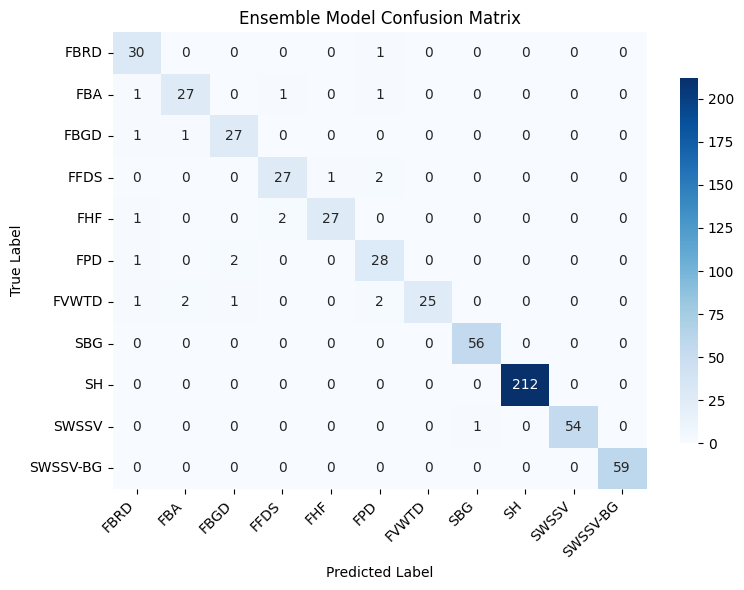

✅ High-Res IEEE Matrix saved to: /content/drive/My Drive/Project_SOTA_Ensemble/ieee_confusion_matrix_acronyms.png


In [ ]:
# @title 🎨 Generate IEEE-Formatted Confusion Matrix (Fully Self-Contained)
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from google.colab import drive

# 1. Re-mount Google Drive FIRST
print("🔌 Re-connecting to Google Drive...")
drive.mount('/content/drive')

# 2. Setup Paths
BASE_DIR = "/content/drive/My Drive/Project_SOTA_Ensemble"
DATA_DIR = os.path.join(BASE_DIR, "dataset_raw")
MODEL_DIR = os.path.join(BASE_DIR, "models")

print("🌊 Loading Test Data and Models...")

# 3. Re-load Test Data
test_datagen = ImageDataGenerator(rescale=1./255)
test_gen = test_datagen.flow_from_directory(
    os.path.join(DATA_DIR, "test"),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False # CRITICAL for matching labels
)

# 4. Re-load Models & Predict
print("♻️ Loading Models and predicting (This takes ~20 seconds)...")
model_a = load_model(os.path.join(MODEL_DIR, "model_A_hybrid.keras"))
model_b = load_model(os.path.join(MODEL_DIR, "model_B_efficientnet.keras"))

pred_a = model_a.predict(test_gen, verbose=0)
pred_b = model_b.predict(test_gen, verbose=0)

# 5. Calculate Ensemble Logic
ensemble_pred_probs = (pred_a + pred_b) / 2
ensemble_classes = np.argmax(ensemble_pred_probs, axis=1)
true_classes = test_gen.classes

# 6. Plot the IEEE Matrix
print("🎨 Generating Confusion Matrix with Acronyms...")
acronym_labels = [
    "FBRD", "FBA", "FBGD", "FFDS", "FHF", "FPD", "FVWTD",
    "SBG", "SH", "SWSSV", "SWSSV-BG"
]

cm = confusion_matrix(true_classes, ensemble_classes)

# Smaller figure size (8x6) to fit a single IEEE column perfectly
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=acronym_labels, yticklabels=acronym_labels,
            cbar_kws={'shrink': 0.8})

plt.title('Ensemble Model Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Rotate labels slightly for perfect readability
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save at 300 DPI - Strict IEEE publication requirement
save_path = os.path.join(BASE_DIR, "ieee_confusion_matrix_acronyms.png")
plt.savefig(save_path, dpi=300)
plt.show()

print(f"✅ High-Res IEEE Matrix saved to: {save_path}")

In [ ]:
# @title 📊 Generate Class-Wise Performance Table
from sklearn.metrics import classification_report
import pandas as pd

print("📊 Calculating Class-Wise Metrics...")

# Generate the raw classification report dictionary
# We use the acronym_labels we defined in the previous block
report = classification_report(true_classes, ensemble_classes, target_names=acronym_labels, output_dict=True)

# Convert to a beautiful Pandas DataFrame
df_class_metrics = pd.DataFrame(report).transpose()

# We only want the specific classes, so we drop the summary rows at the bottom
# (accuracy, macro avg, weighted avg) and the 'support' column
df_class_metrics = df_class_metrics.iloc[:-3, :-1]

# Convert decimals to percentages and format nicely
df_class_metrics = (df_class_metrics * 100).round(2).astype(str) + '%'

# Rename columns for IEEE professionalism
df_class_metrics.columns = ['Precision', 'Recall', 'F1-Score']

print("\n🏆 CLASS-WISE PERFORMANCE METRICS 🏆")
print("-" * 50)
print(df_class_metrics.to_markdown())
print("-" * 50)

# Save to a CSV so you can easily copy-paste it into your Word doc!
csv_path = os.path.join(BASE_DIR, "ieee_class_wise_metrics.csv")
df_class_metrics.to_csv(csv_path)
print(f"\n✅ Table saved for Word copy-pasting at: {csv_path}")

📊 Calculating Class-Wise Metrics...

🏆 CLASS-WISE PERFORMANCE METRICS 🏆
--------------------------------------------------
|          | Precision   | Recall   | F1-Score   |
|:---------|:------------|:---------|:-----------|
| FBRD     | 85.71%      | 96.77%   | 90.91%     |
| FBA      | 90.0%       | 90.0%    | 90.0%      |
| FBGD     | 90.0%       | 93.1%    | 91.53%     |
| FFDS     | 90.0%       | 90.0%    | 90.0%      |
| FHF      | 96.43%      | 90.0%    | 93.1%      |
| FPD      | 82.35%      | 90.32%   | 86.15%     |
| FVWTD    | 100.0%      | 80.65%   | 89.29%     |
| SBG      | 98.25%      | 100.0%   | 99.12%     |
| SH       | 100.0%      | 100.0%   | 100.0%     |
| SWSSV    | 100.0%      | 98.18%   | 99.08%     |
| SWSSV-BG | 100.0%      | 100.0%   | 100.0%     |
--------------------------------------------------

✅ Table saved for Word copy-pasting at: /content/drive/My Drive/Project_SOTA_Ensemble/ieee_class_wise_metrics.csv


📈 Generating Comparative SOTA Bar Chart...


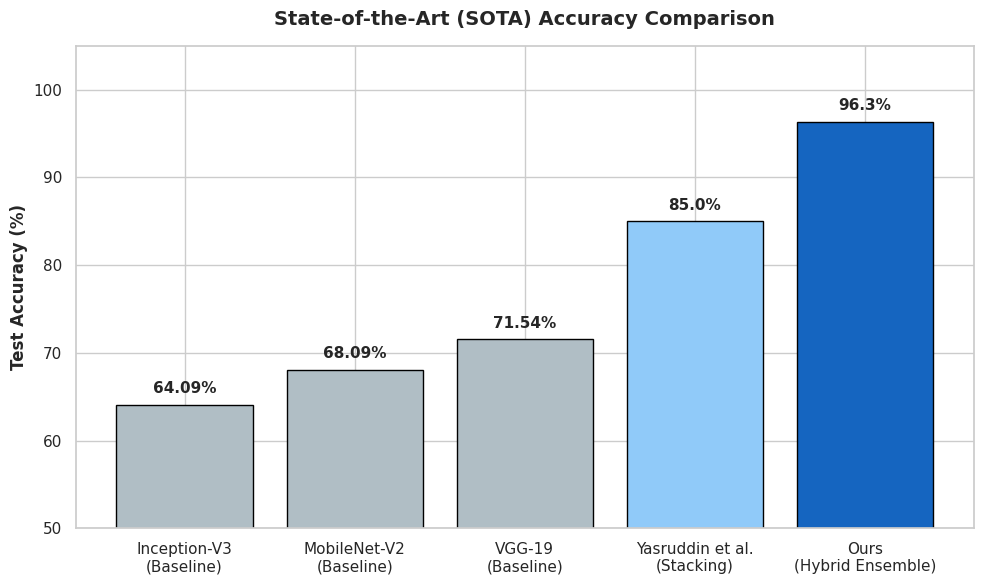

✅ SOTA Chart saved at: /content/drive/My Drive/Project_SOTA_Ensemble/ieee_sota_comparison_chart.png


In [ ]:
# @title 📈 Generate SOTA Comparison Bar Chart
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("📈 Generating Comparative SOTA Bar Chart...")

# Data extracted straight from your literature review!
models = ['Inception-V3\n(Baseline)', 'MobileNet-V2\n(Baseline)', 'VGG-19\n(Baseline)', 'Yasruddin et al.\n(Stacking)', 'Ours\n(Hybrid Ensemble)']
accuracies = [64.09, 68.09, 71.54, 85.00, 96.30]

# Set up the plot style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Create the bars, giving "Ours" a distinct, strong color
colors = ['#B0BEC5', '#B0BEC5', '#B0BEC5', '#90CAF9', '#1565C0']
bars = plt.bar(models, accuracies, color=colors, edgecolor='black', linewidth=1)

# Add the exact percentages on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval}%',
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.title('State-of-the-Art (SOTA) Accuracy Comparison', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Test Accuracy (%)', fontsize=12, fontweight='bold')
plt.ylim(50, 105) # Start at 50 to visually emphasize the performance gap

plt.tight_layout()

# Save at high resolution for IEEE
save_path = os.path.join(BASE_DIR, "ieee_sota_comparison_chart.png")
plt.savefig(save_path, dpi=300)
plt.show()

print(f"✅ SOTA Chart saved at: {save_path}")

🔍 Initializing Explainable AI (XAI) Grad-CAM Module...
♻️ Loading Model B for Texture Feature Analysis...
🔥 Generating Heatmap for: Fish_Bacterial_Red_disease...


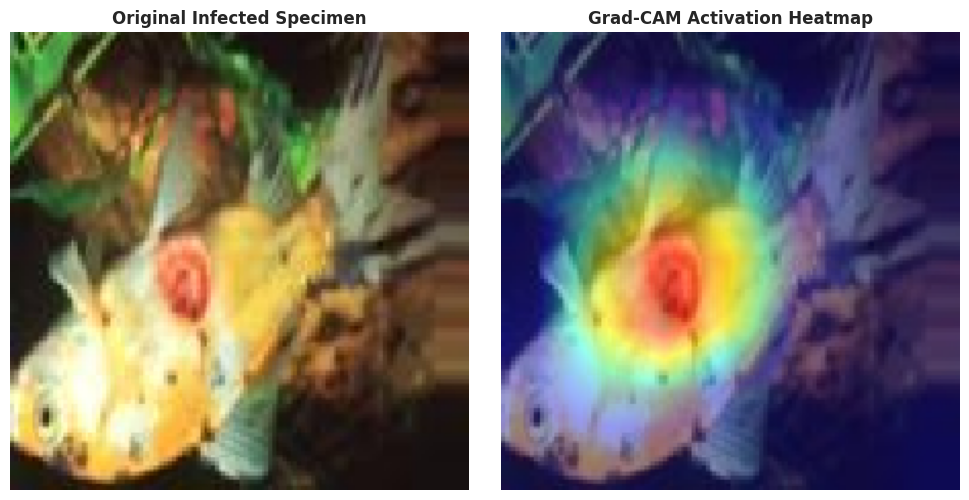

✅ XAI Figure saved successfully at: /content/drive/My Drive/Project_SOTA_Ensemble/ieee_gradcam_heatmap.png


In [ ]:
# @title 🔍 Generate XAI Grad-CAM Heatmaps (Corrected OpenCV Flag)
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

print("🔍 Initializing Explainable AI (XAI) Grad-CAM Module...")

# 1. Setup Paths
BASE_DIR = "/content/drive/My Drive/Project_SOTA_Ensemble"
DATA_DIR = os.path.join(BASE_DIR, "dataset_raw")
MODEL_DIR = os.path.join(BASE_DIR, "models")

# 2. Load Model B
print("♻️ Loading Model B for Texture Feature Analysis...")
model_b = load_model(os.path.join(MODEL_DIR, "model_B_efficientnet.keras"))

# 3. Split the Nested Model for Grad-CAM
base_model = model_b.layers[1]
feature_extractor = tf.keras.models.Model(
    inputs=base_model.inputs,
    outputs=base_model.get_layer('top_activation').output
)

head_input = tf.keras.Input(shape=feature_extractor.output_shape[1:])
x = model_b.layers[2](head_input)
x = model_b.layers[3](x)
head_output = model_b.layers[4](x)
classifier = tf.keras.models.Model(inputs=head_input, outputs=head_output)

# 4. Setup Grad-CAM Algorithm
def make_gradcam_heatmap(img_array, feature_extractor, classifier):
    with tf.GradientTape() as tape:
        last_conv_layer_output = feature_extractor(img_array)
        tape.watch(last_conv_layer_output)

        preds = classifier(last_conv_layer_output)
        pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# 5. Pick a Sample Image
sample_class = "Fish_Bacterial_Red_disease"
sample_folder = os.path.join(DATA_DIR, "test", sample_class)
sample_image_name = os.listdir(sample_folder)[0]
img_path = os.path.join(sample_folder, sample_image_name)

# Prepare Image
img = load_img(img_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array_scaled = np.expand_dims(img_array / 255.0, axis=0)

# Generate Heatmap
print(f"🔥 Generating Heatmap for: {sample_class}...")
heatmap = make_gradcam_heatmap(img_array_scaled, feature_extractor, classifier)

# 6. Overlay Heatmap on Original Image
heatmap_resized = cv2.resize(heatmap, (img.size[0], img.size[1]))
heatmap_resized = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)

# THE BUG FIX IS HERE:
original_img_bgr = cv2.cvtColor(np.uint8(img_array), cv2.COLOR_RGB2BGR)
superimposed_img = cv2.addWeighted(original_img_bgr, 0.6, heatmap_colored, 0.4, 0)
superimposed_img_rgb = cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB)

# 7. Plot the IEEE-Ready Figure
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(np.uint8(img_array))
axes[0].set_title("Original Infected Specimen", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(superimposed_img_rgb)
axes[1].set_title("Grad-CAM Activation Heatmap", fontweight='bold')
axes[1].axis('off')

plt.tight_layout()

# Save for your Word Document
save_path = os.path.join(BASE_DIR, "ieee_gradcam_heatmap.png")
plt.savefig(save_path, dpi=300)
plt.show()

print(f"✅ XAI Figure saved successfully at: {save_path}")

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

# Data for the charts
models = ['Inception-V3', 'MobileNet-V2', 'VGG-16', 'Stacking', 'Proposed Model']
metrics = {
    'Accuracy': [64.09, 68.09, 71.54, 85.00, 96.30],
    'Precision': [63.50, 67.20, 70.80, 84.10, 93.89],
    'Recall': [62.10, 66.80, 71.00, 83.50, 93.55],
    'F1-Score': [62.80, 67.00, 70.90, 83.80, 93.56]
}

# 🎨 NEW: Completely distinct, vibrant colors for each bar
# Deep Orange, Amber, Mint Green, Purple, and Strong Blue
colors = ['#FF7043', '#FFCA28', '#66BB6A', '#AB47BC', '#1E88E5']

# Generate and save a chart for each metric
for metric_name, values in metrics.items():
    plt.figure(figsize=(8, 5))
    bars = plt.bar(models, values, color=colors, edgecolor='black', linewidth=1.2)

    # Add values on top of bars
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval}%', ha='center', va='bottom', fontweight='bold')

    plt.ylim(50, 105) # Keeps the y-axis consistent
    plt.ylabel(f'{metric_name} (%)', fontweight='bold', fontsize=12)
    plt.title(f'State-of-the-Art (SOTA) {metric_name} Comparison', fontweight='bold', fontsize=14)
    plt.tight_layout()

    # Save the file temporarily, then trigger the browser download
    filename = f'fig_{metric_name.lower()}.png'
    plt.savefig(filename, dpi=300)
    plt.close()

    files.download(filename)

print("All 4 distinct-color charts downloaded successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All 4 distinct-color charts downloaded successfully!
